# **Perfil dos Estudantes Brasileiros — Analytics Educacional**

> Análise exploratória e territorial da educação brasileira com dados públicos do INEP, cobrindo os anos disponíveis desde 2015.

Este notebook integra dados da Educação Básica e do Ensino Superior para investigar evolução de matrículas, desigualdades regionais, infraestrutura, inclusão, perfil demográfico e políticas de permanência. A consulta foi estruturada para ser reproduzível e atualizar automaticamente o ano final conforme a disponibilidade da fonte.

## Fontes de dados

As fontes são acessadas por meio da [Base dos Dados](https://basedosdados.org/) no Google BigQuery:

- Censo Escolar — matrícula;
- Censo Escolar — escola;
- Censo da Educação Superior — curso;
- Censo da Educação Superior — instituição de ensino;
- diretório de municípios.

A consulta aplica `2015` como ano inicial e `EXTRACT(YEAR FROM CURRENT_DATE())` como limite superior. O ano corrente do calendário só aparecerá se já estiver disponível na fonte.

## Objetivo analítico

Construir uma base agregada para responder perguntas de negócio e pesquisa:

1. Como evoluíram as matrículas por nível de ensino, região e ano?
2. Como variaram conectividade, inclusão e infraestrutura escolar?
3. Quais diferenças aparecem entre redes, regiões e perfis demográficos?
4. Quais municípios podem apresentar perfis semelhantes de infraestrutura?

> **Escopo:** este notebook realiza a consulta, a análise exploratória e os diagnósticos visuais. Clusterização, classificação e previsão serão desenvolvidas em notebooks derivados das bases SQL específicas do projeto.

### Notas metodológicas

- A saída é agregada por dimensões analíticas; não representa uma linha individual por estudante.
- `qtd_estudantes` representa registros ou matrículas disponíveis na fonte para cada agrupamento.
- Percentuais não devem ser somados entre linhas.
- Para indicadores percentuais, as comparações nacionais usam média ponderada por `qtd_estudantes` quando essa ponderação é metodologicamente adequada.
- Educação Básica e Ensino Superior possuem dimensões diferentes; valores nulos podem significar que o indicador não se aplica àquela fonte.

## **1. Configuração e Preparação do Ambiente**

### **1.1. Importação de Bibliotecas e Instalações**

In [1]:
# Dependências e configuração
!pip -q install basedosdados

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import basedosdados as bd
from matplotlib.ticker import FuncFormatter

# Use um projeto Google Cloud próprio para cobrança/quota do BigQuery.
# Substitua pelo ID do seu projeto antes de executar a consulta.
project_id = 'estudosdados-489915'

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titleweight'] = 'bold'

print(f'Projeto de cobrança configurado: {project_id}')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.2/96.2 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 347.9/347.9 kB 11.0 MB/s eta 0:00:00
Projeto de cobrança configurado: estudosdados-489915


### **1.2. Definição e Execução da Consulta SQL (Google BigQuery)**

In [2]:
query = """
/*==============================================================================
PROJETO
------------------------------------------------------------------------------
Perfil dos Estudantes Brasileiros (2015–ano corrente)

OBJETIVO
------------------------------------------------------------------------------
Construir uma base analítica consolidada sobre o perfil dos estudantes
brasileiros dos ensinos Fundamental, Médio e Superior, utilizando dados públicos
do INEP disponibilizados na Base dos Dados e consultados no Google BigQuery.

DESCRIÇÃO DA SOLUÇÃO
------------------------------------------------------------------------------
Este script integra dados do Censo Escolar, Censo da Educação Superior e
Diretório de Municípios, criando uma visão única para análise demográfica,
geográfica, institucional, social e de infraestrutura escolar.

FONTES DE DADOS
------------------------------------------------------------------------------
1. basedosdados.br_inep_censo_escolar.matricula
2. basedosdados.br_inep_censo_escolar.escola
3. basedosdados.br_inep_censo_educacao_superior.curso
4. basedosdados.br_inep_censo_educacao_superior.ies
5. basedosdados.br_bd_diretorios_brasil.municipio

JANELA TEMPORAL
------------------------------------------------------------------------------
2015 até o ano corrente no momento da execução.

A janela final é dinâmica e usa EXTRACT(YEAR FROM CURRENT_DATE()).

==============================================================================*/

DECLARE ano_inicio INT64 DEFAULT 2015;
DECLARE ano_fim INT64 DEFAULT EXTRACT(YEAR FROM CURRENT_DATE());

/*==============================================================================
CTE: educacao_basica
------------------------------------------------------------------------------
Consolida dados da Educação Básica: Ensino Fundamental e Ensino Médio.
==============================================================================*/
WITH educacao_basica AS (
  SELECT
    m.ano,
    'CENSO_ESCOLAR' AS fonte,

    -- Classificação das etapas de ensino.
    CASE
      WHEN CAST(m.etapa_ensino AS STRING) IN ('14','15','16','17','18','19','20','21','41') THEN 'ENSINO_FUNDAMENTAL'
      WHEN CAST(m.etapa_ensino AS STRING) IN ('25','26','27','28','29','30','31','32','33','34','35','36','37','38') THEN 'ENSINO_MEDIO'
      ELSE 'OUTRA_ETAPA'
    END AS nivel_ensino,

    m.sigla_uf,
    m.id_municipio,
    mun.nome AS nome_municipio,

    CAST(m.id_escola AS STRING) AS id_unidade_ensino,
    CAST(NULL AS STRING) AS nome_unidade_ensino,
    CAST(NULL AS STRING) AS id_curso,
    CAST(NULL AS STRING) AS nome_curso,
    CAST(NULL AS STRING) AS area_conhecimento,

    m.sexo,
    m.raca_cor,
    m.idade,
    m.nacionalidade,

    -- Tradução do código da rede de ensino da Educação Básica.
    CASE
      WHEN CAST(m.rede AS STRING) = '1' THEN 'Federal'
      WHEN CAST(m.rede AS STRING) = '2' THEN 'Estadual'
      WHEN CAST(m.rede AS STRING) = '3' THEN 'Municipal'
      WHEN CAST(m.rede AS STRING) = '4' THEN 'Privada'
      ELSE 'Não Informado'
    END AS rede,

    e.tipo_localizacao,
    e.tipo_localizacao_diferenciada,

    CAST(NULL AS STRING) AS tipo_modalidade_ensino,
    CAST(NULL AS STRING) AS tipo_grau_academico,
    CAST(NULL AS STRING) AS tipo_organizacao_academica,
    CAST(NULL AS STRING) AS tipo_organizacao_administrativa,

    -- Métrica principal da Educação Básica.
    COUNT(*) AS qtd_estudantes,

    -- Indicadores de inclusão e transporte.
    COUNTIF(CAST(m.necessidade_especial AS STRING) IN ('1','true','TRUE')) AS qtd_com_deficiencia,
    COUNTIF(CAST(m.transporte_publico AS STRING) IN ('1','true','TRUE')) AS qtd_usa_transporte_publico,

    -- Indicadores de infraestrutura escolar.
    COUNTIF(CAST(e.agua_potavel AS STRING) IN ('1','true','TRUE')) AS qtd_em_escola_com_agua_potavel,
    COUNTIF(CAST(e.energia_rede_publica AS STRING) IN ('1','true','TRUE')) AS qtd_em_escola_com_energia_rede_publica,
    COUNTIF(CAST(e.esgoto_rede_publica AS STRING) IN ('1','true','TRUE')) AS qtd_em_escola_com_esgoto_rede_publica,
    COUNTIF(CAST(e.internet AS STRING) IN ('1','true','TRUE')) AS qtd_em_escola_com_internet,
    COUNTIF(CAST(e.internet_alunos AS STRING) IN ('1','true','TRUE')) AS qtd_em_escola_com_internet_alunos,
    COUNTIF(CAST(e.biblioteca AS STRING) IN ('1','true','TRUE')) AS qtd_em_escola_com_biblioteca,
    COUNTIF(CAST(e.biblioteca_sala_leitura AS STRING) IN ('1','true','TRUE')) AS qtd_em_escola_com_biblioteca_sala_leitura,
    COUNTIF(CAST(e.laboratorio_informatica AS STRING) IN ('1','true','TRUE')) AS qtd_em_escola_com_lab_informatica,
    COUNTIF(CAST(e.laboratorio_ciencias AS STRING) IN ('1','true','TRUE')) AS qtd_em_escola_com_lab_ciencias,
    COUNTIF(CAST(e.quadra_esportes AS STRING) IN ('1','true','TRUE')) AS qtd_em_escola_com_quadra,

    -- Campos exclusivos do Ensino Superior.
    CAST(NULL AS INT64) AS qtd_financiamento,
    CAST(NULL AS INT64) AS qtd_reserva_vaga,
    CAST(NULL AS INT64) AS qtd_apoio_social,
    CAST(NULL AS INT64) AS qtd_atividade_extracurricular,
    CAST(NULL AS INT64) AS qtd_mobilidade_academica

  FROM `basedosdados.br_inep_censo_escolar.matricula` AS m

  LEFT JOIN `basedosdados.br_inep_censo_escolar.escola` AS e
    ON m.ano = e.ano
   AND m.id_escola = e.id_escola

  LEFT JOIN `basedosdados.br_bd_diretorios_brasil.municipio` AS mun
    ON m.id_municipio = mun.id_municipio

  WHERE m.ano BETWEEN ano_inicio AND ano_fim
    AND CAST(m.etapa_ensino AS STRING) IN (
      '14','15','16','17','18','19','20','21','41',
      '25','26','27','28','29','30','31','32','33','34','35','36','37','38'
    )

  GROUP BY
    m.ano,
    nivel_ensino,
    m.sigla_uf,
    m.id_municipio,
    nome_municipio,
    id_unidade_ensino,
    m.sexo,
    m.raca_cor,
    m.idade,
    m.nacionalidade,
    rede,
    e.tipo_localizacao,
    e.tipo_localizacao_diferenciada
),


/*==============================================================================
CTE: educacao_superior
------------------------------------------------------------------------------
Consolida dados do Ensino Superior.
==============================================================================*/
educacao_superior AS (
  SELECT
    c.ano,
    'CENSO_SUPERIOR' AS fonte,
    'ENSINO_SUPERIOR' AS nivel_ensino,

    c.sigla_uf,
    c.id_municipio,
    mun.nome AS nome_municipio,

    CAST(c.id_ies AS STRING) AS id_unidade_ensino,
    i.nome AS nome_unidade_ensino,
    CAST(c.id_curso AS STRING) AS id_curso,
    c.nome_curso,
    c.nome_area_geral AS area_conhecimento,

    -- Campos demográficos agregados no Ensino Superior.
    'AGREGADO' AS sexo,
    'AGREGADO' AS raca_cor,
    CAST(NULL AS INT64) AS idade,
    'AGREGADO' AS nacionalidade,

    -- Tradução do código da rede de ensino do Ensino Superior.
    CASE
      WHEN CAST(c.rede AS STRING) = '1' THEN 'Pública'
      WHEN CAST(c.rede AS STRING) = '2' THEN 'Privada'
      ELSE 'Não Informado'
    END AS rede,

    CAST(NULL AS STRING) AS tipo_localizacao,
    CAST(NULL AS STRING) AS tipo_localizacao_diferenciada,

    c.tipo_modalidade_ensino,
    c.tipo_grau_academico,
    c.tipo_organizacao_academica,
    c.tipo_organizacao_administrativa,

    -- Métrica principal do Ensino Superior.
    -- COALESCE evita que uma célula nula anule o total do agrupamento.
    COALESCE(SUM(c.quantidade_matriculas), 0) AS qtd_estudantes,

    -- Indicador de inclusão no Ensino Superior.
    COALESCE(SUM(c.quantidade_matriculas_deficiencia), 0) AS qtd_com_deficiencia,

    CAST(NULL AS INT64) AS qtd_usa_transporte_publico,

    -- Campos de infraestrutura aplicáveis apenas à Educação Básica.
    CAST(NULL AS INT64) AS qtd_em_escola_com_agua_potavel,
    CAST(NULL AS INT64) AS qtd_em_escola_com_energia_rede_publica,
    CAST(NULL AS INT64) AS qtd_em_escola_com_esgoto_rede_publica,
    CAST(NULL AS INT64) AS qtd_em_escola_com_internet,
    CAST(NULL AS INT64) AS qtd_em_escola_com_internet_alunos,
    CAST(NULL AS INT64) AS qtd_em_escola_com_biblioteca,
    CAST(NULL AS INT64) AS qtd_em_escola_com_biblioteca_sala_leitura,
    CAST(NULL AS INT64) AS qtd_em_escola_com_lab_informatica,
    CAST(NULL AS INT64) AS qtd_em_escola_com_lab_ciencias,
    CAST(NULL AS INT64) AS qtd_em_escola_com_quadra,

    -- Indicadores específicos do Ensino Superior.
    COALESCE(SUM(c.quantidade_matriculas_financiamento), 0) AS qtd_financiamento,
    COALESCE(SUM(c.quantidade_matriculas_reserva_vaga), 0) AS qtd_reserva_vaga,
    COALESCE(SUM(c.quantidade_matriculas_apoio_social), 0) AS qtd_apoio_social,
    COALESCE(SUM(c.quantidade_matriculas_atividade_extracurricular), 0) AS qtd_atividade_extracurricular,
    COALESCE(SUM(c.quantidade_matriculas_mobilidade_academica), 0) AS qtd_mobilidade_academica

  FROM `basedosdados.br_inep_censo_educacao_superior.curso` AS c

  LEFT JOIN `basedosdados.br_inep_censo_educacao_superior.ies` AS i
    ON c.ano = i.ano
   AND c.id_ies = i.id_ies

  LEFT JOIN `basedosdados.br_bd_diretorios_brasil.municipio` AS mun
    ON c.id_municipio = mun.id_municipio

  WHERE c.ano BETWEEN ano_inicio AND ano_fim

  GROUP BY
    c.ano,
    c.sigla_uf,
    c.id_municipio,
    nome_municipio,
    id_unidade_ensino,
    nome_unidade_ensino,
    id_curso,
    c.nome_curso,
    area_conhecimento,
    rede,
    c.tipo_modalidade_ensino,
    c.tipo_grau_academico,
    c.tipo_organizacao_academica,
    c.tipo_organizacao_administrativa
),


/*==============================================================================
CTE: base_unificada
------------------------------------------------------------------------------
Une os dados da Educação Básica e do Ensino Superior.
==============================================================================*/
base_unificada AS (
  SELECT * FROM educacao_basica
  UNION ALL
  SELECT * FROM educacao_superior
)


/*==============================================================================
RESULTADO FINAL COMPLETO (Todos os Níveis de Ensino)
------------------------------------------------------------------------------
Retorna a tabela analítica unificada com todas as quebras originais.
==============================================================================*/
SELECT
  ano,
  fonte,
  nivel_ensino,
  sigla_uf,
  id_municipio,
  nome_municipio,

  -- Classificação da região geográfica.
  CASE
    WHEN sigla_uf IN ('AC','AP','AM','PA','RO','RR','TO') THEN 'NORTE'
    WHEN sigla_uf IN ('AL','BA','CE','MA','PB','PE','PI','RN','SE') THEN 'NORDESTE'
    WHEN sigla_uf IN ('DF','GO','MT','MS') THEN 'CENTRO-OESTE'
    WHEN sigla_uf IN ('ES','MG','RJ','SP') THEN 'SUDESTE'
    WHEN sigla_uf IN ('PR','RS','SC') THEN 'SUL'
    ELSE 'NAO_IDENTIFICADO'
  END AS regiao,

  sexo,
  raca_cor,

  -- Criação de faixas etárias.
  CASE
    WHEN idade IS NULL THEN 'AGREGADO_SUPERIOR'
    WHEN idade BETWEEN 0 AND 5 THEN '00 A 05'
    WHEN idade BETWEEN 6 AND 10 THEN '06 A 10'
    WHEN idade BETWEEN 11 AND 14 THEN '11 A 14'
    WHEN idade BETWEEN 15 AND 17 THEN '15 A 17'
    WHEN idade BETWEEN 18 AND 24 THEN '18 A 24'
    WHEN idade BETWEEN 25 AND 29 THEN '25 A 29'
    WHEN idade BETWEEN 30 AND 34 THEN '30 A 34'
    WHEN idade BETWEEN 35 AND 39 THEN '35 A 39'
    WHEN idade BETWEEN 40 AND 49 THEN '40 A 49'
    WHEN idade BETWEEN 50 AND 59 THEN '50 A 59'
    WHEN idade >= 60 THEN '60+'
    ELSE 'NAO_INFORMADO'
  END AS faixa_etaria,

  nacionalidade,
  rede,
  tipo_localizacao,
  tipo_localizacao_diferenciada,
  tipo_modalidade_ensino,
  tipo_grau_academico,
  tipo_organizacao_academica,
  tipo_organizacao_administrativa,
  area_conhecimento,

  -- Métricas principais.
  SUM(qtd_estudantes) AS qtd_estudantes,
  SUM(qtd_com_deficiencia) AS qtd_com_deficiencia,
  SUM(qtd_usa_transporte_publico) AS qtd_usa_transporte_publico,

  -- Métricas de infraestrutura escolar.
  SUM(qtd_em_escola_com_agua_potavel) AS qtd_em_escola_com_agua_potavel,
  SUM(qtd_em_escola_com_energia_rede_publica) AS qtd_em_escola_com_energia_rede_publica,
  SUM(qtd_em_escola_com_esgoto_rede_publica) AS qtd_em_escola_com_esgoto_rede_publica,
  SUM(qtd_em_escola_com_internet) AS qtd_em_escola_com_internet,
  SUM(qtd_em_escola_com_internet_alunos) AS qtd_em_escola_com_internet_alunos,
  SUM(qtd_em_escola_com_biblioteca) AS qtd_em_escola_com_biblioteca,
  SUM(qtd_em_escola_com_biblioteca_sala_leitura) AS qtd_em_escola_com_biblioteca_sala_leitura,
  SUM(qtd_em_escola_com_lab_informatica) AS qtd_em_escola_com_lab_informatica,
  SUM(qtd_em_escola_com_lab_ciencias) AS qtd_em_escola_com_lab_ciencias,
  SUM(qtd_em_escola_com_quadra) AS qtd_em_escola_com_quadra,

  -- Métricas específicas do Ensino Superior.
  SUM(qtd_financiamento) AS qtd_financiamento,
  SUM(qtd_reserva_vaga) AS qtd_reserva_vaga,
  SUM(qtd_apoio_social) AS qtd_apoio_social,
  SUM(qtd_atividade_extracurricular) AS qtd_atividade_extracurricular,
  SUM(qtd_mobilidade_academica) AS qtd_mobilidade_academica,

  -- Indicadores percentuais.
  ROUND(SAFE_DIVIDE(SUM(qtd_com_deficiencia), SUM(qtd_estudantes)) * 100, 2) AS perc_com_deficiencia,
  ROUND(SAFE_DIVIDE(SUM(qtd_usa_transporte_publico), SUM(qtd_estudantes)) * 100, 2) AS perc_usa_transporte_publico,
  ROUND(SAFE_DIVIDE(SUM(qtd_em_escola_com_agua_potavel), SUM(qtd_estudantes)) * 100, 2) AS perc_em_escola_com_agua_potavel,
  ROUND(SAFE_DIVIDE(SUM(qtd_em_escola_com_energia_rede_publica), SUM(qtd_estudantes)) * 100, 2) AS perc_em_escola_com_energia_rede_publica,
  ROUND(SAFE_DIVIDE(SUM(qtd_em_escola_com_esgoto_rede_publica), SUM(qtd_estudantes)) * 100, 2) AS perc_em_escola_com_esgoto_rede_publica,
  ROUND(SAFE_DIVIDE(SUM(qtd_em_escola_com_internet), SUM(qtd_estudantes)) * 100, 2) AS perc_em_escola_com_internet,
  ROUND(SAFE_DIVIDE(SUM(qtd_em_escola_com_internet_alunos), SUM(qtd_estudantes)) * 100, 2) AS perc_em_escola_com_internet_alunos,
  ROUND(SAFE_DIVIDE(SUM(qtd_em_escola_com_biblioteca), SUM(qtd_estudantes)) * 100, 2) AS perc_em_escola_com_biblioteca,
  ROUND(SAFE_DIVIDE(SUM(qtd_em_escola_com_biblioteca_sala_leitura), SUM(qtd_estudantes)) * 100, 2) AS perc_em_escola_com_biblioteca_sala_leitura,
  ROUND(SAFE_DIVIDE(SUM(qtd_em_escola_com_lab_informatica), SUM(qtd_estudantes)) * 100, 2) AS perc_em_escola_com_lab_informatica,
  ROUND(SAFE_DIVIDE(SUM(qtd_em_escola_com_lab_ciencias), SUM(qtd_estudantes)) * 100, 2) AS perc_em_escola_com_lab_ciencias,
  ROUND(SAFE_DIVIDE(SUM(qtd_em_escola_com_quadra), SUM(qtd_estudantes)) * 100, 2) AS perc_em_escola_com_quadra,
  ROUND(SAFE_DIVIDE(SUM(qtd_financiamento), SUM(qtd_estudantes)) * 100, 2) AS perc_financiamento,
  ROUND(SAFE_DIVIDE(SUM(qtd_reserva_vaga), SUM(qtd_estudantes)) * 100, 2) AS perc_reserva_vaga,
  ROUND(SAFE_DIVIDE(SUM(qtd_apoio_social), SUM(qtd_estudantes)) * 100, 2) AS perc_apoio_social,
  ROUND(SAFE_DIVIDE(SUM(qtd_atividade_extracurricular), SUM(qtd_estudantes)) * 100, 2) AS perc_atividade_extracurricular,
  ROUND(SAFE_DIVIDE(SUM(qtd_mobilidade_academica), SUM(qtd_estudantes)) * 100, 2) AS perc_mobilidade_academica

FROM base_unificada

GROUP BY
  ano,
  fonte,
  nivel_ensino,
  sigla_uf,
  id_municipio,
  nome_municipio,
  regiao,
  sexo,
  raca_cor,
  faixa_etaria,
  nacionalidade,
  rede,
  tipo_localizacao,
  tipo_localizacao_diferenciada,
  tipo_modalidade_ensino,
  tipo_grau_academico,
  tipo_organizacao_academica,
  tipo_organizacao_administrativa,
  area_conhecimento

ORDER BY
  ano,
  regiao,
  sigla_uf,
  nome_municipio,
  nivel_ensino,
  qtd_estudantes DESC
"""
# df_001 >> DataFrame 001
# Executa a query SQL utilizando a biblioteca basedosdados e armazena o resultado em um DataFrame pandas (df_001)
df_001 = bd.read_sql(query, billing_project_id=project_id)
# Imprime as dimensões (linhas, colunas) do DataFrame carregado
print(df_001.shape)

Downloading: 100%|██████████|
(4582798, 54)


## 2. Análise exploratória de dados (EDA)

Nesta etapa verificamos a estrutura, a cobertura temporal, a qualidade básica e as dimensões disponíveis antes de interpretar os gráficos.

### **2.1. Inspeção Estrutural e Estatísticas Descritivas**

In [3]:
# Perfil estrutural da base
print(f'Linhas: {df_001.shape[0]:,}'.replace(',', '.'))
print(f'Colunas: {df_001.shape[1]}')
display(df_001.head())
display(df_001.dtypes.rename('tipo').to_frame())

# Percentual de valores nulos por coluna, priorizando os maiores valores.
missing = (df_001.isna().mean().mul(100).round(2)
           .sort_values(ascending=False)
           .rename('percentual_nulo')
           .to_frame())
display(missing.head(15))

Linhas: 4.582.798
Colunas: 54


,ano,fonte,nivel_ensino,sigla_uf,id_municipio,nome_municipio,regiao,sexo,raca_cor,faixa_etaria,...,perc_em_escola_com_biblioteca,perc_em_escola_com_biblioteca_sala_leitura,perc_em_escola_com_lab_informatica,perc_em_escola_com_lab_ciencias,perc_em_escola_com_quadra,perc_financiamento,perc_reserva_vaga,perc_apoio_social,perc_atividade_extracurricular,perc_mobilidade_academica
0,2015,CENSO_ESCOLAR,ENSINO_FUNDAMENTAL,DF,5300108,Brasília,CENTRO-OESTE,1,3,06 A 10,...,24.44,91.04,89.96,11.31,67.01,NaN,NaN,NaN,NaN,NaN
1,2015,CENSO_ESCOLAR,ENSINO_FUNDAMENTAL,DF,5300108,Brasília,CENTRO-OESTE,1,3,11 A 14,...,37.32,96.64,89.62,26.53,86.77,NaN,NaN,NaN,NaN,NaN
2,2015,CENSO_ESCOLAR,ENSINO_FUNDAMENTAL,DF,5300108,Brasília,CENTRO-OESTE,2,3,11 A 14,...,37.58,97.24,89.45,27.06,88.46,NaN,NaN,NaN,NaN,NaN
3,2015,CENSO_ESCOLAR,ENSINO_FUNDAMENTAL,DF,5300108,Brasília,CENTRO-OESTE,2,3,06 A 10,...,23.92,90.52,89.99,10.76,66.77,NaN,NaN,NaN,NaN,NaN
4,2015,CENSO_ESCOLAR,ENSINO_FUNDAMENTAL,DF,5300108,Brasília,CENTRO-OESTE,1,0,11 A 14,...,42.14,97.27,92.40,31.01,85.81,NaN,NaN,NaN,NaN,NaN


,tipo
ano,Int64
fonte,object
nivel_ensino,object
sigla_uf,object
id_municipio,object
nome_municipio,object
regiao,object
sexo,object
raca_cor,object
faixa_etaria,object


,percentual_nulo
perc_atividade_extracurricular,88.14
perc_reserva_vaga,88.14
perc_financiamento,88.14
perc_apoio_social,88.14
perc_mobilidade_academica,88.14
tipo_grau_academico,87.18
qtd_atividade_extracurricular,87.09
qtd_financiamento,87.09
qtd_apoio_social,87.09
tipo_organizacao_administrativa,87.09


In [4]:
# Exibe as primeiras 5 linhas do DataFrame para uma visualização rápida dos dados
df_001.head()

,ano,fonte,nivel_ensino,sigla_uf,id_municipio,nome_municipio,regiao,sexo,raca_cor,faixa_etaria,...,perc_em_escola_com_biblioteca,perc_em_escola_com_biblioteca_sala_leitura,perc_em_escola_com_lab_informatica,perc_em_escola_com_lab_ciencias,perc_em_escola_com_quadra,perc_financiamento,perc_reserva_vaga,perc_apoio_social,perc_atividade_extracurricular,perc_mobilidade_academica
0,2015,CENSO_ESCOLAR,ENSINO_FUNDAMENTAL,DF,5300108,Brasília,CENTRO-OESTE,1,3,06 A 10,...,24.44,91.04,89.96,11.31,67.01,NaN,NaN,NaN,NaN,NaN
1,2015,CENSO_ESCOLAR,ENSINO_FUNDAMENTAL,DF,5300108,Brasília,CENTRO-OESTE,1,3,11 A 14,...,37.32,96.64,89.62,26.53,86.77,NaN,NaN,NaN,NaN,NaN
2,2015,CENSO_ESCOLAR,ENSINO_FUNDAMENTAL,DF,5300108,Brasília,CENTRO-OESTE,2,3,11 A 14,...,37.58,97.24,89.45,27.06,88.46,NaN,NaN,NaN,NaN,NaN
3,2015,CENSO_ESCOLAR,ENSINO_FUNDAMENTAL,DF,5300108,Brasília,CENTRO-OESTE,2,3,06 A 10,...,23.92,90.52,89.99,10.76,66.77,NaN,NaN,NaN,NaN,NaN
4,2015,CENSO_ESCOLAR,ENSINO_FUNDAMENTAL,DF,5300108,Brasília,CENTRO-OESTE,1,0,11 A 14,...,42.14,97.27,92.40,31.01,85.81,NaN,NaN,NaN,NaN,NaN


In [5]:
# Gera estatísticas descritivas das colunas numéricas do DataFrame, como contagem, média, desvio padrão, mínimo, máximo e quartis
df_001.describe()

,ano,qtd_estudantes,qtd_com_deficiencia,qtd_usa_transporte_publico,qtd_em_escola_com_agua_potavel,qtd_em_escola_com_energia_rede_publica,qtd_em_escola_com_esgoto_rede_publica,qtd_em_escola_com_internet,qtd_em_escola_com_internet_alunos,qtd_em_escola_com_biblioteca,...,perc_em_escola_com_biblioteca,perc_em_escola_com_biblioteca_sala_leitura,perc_em_escola_com_lab_informatica,perc_em_escola_com_lab_ciencias,perc_em_escola_com_quadra,perc_financiamento,perc_reserva_vaga,perc_apoio_social,perc_atividade_extracurricular,perc_mobilidade_academica
count,4582798.0,4582798.0,4582798.0,3991357.0,3991357.0,3991357.0,3991357.0,3991357.0,3991357.0,3991357.0,...,3.991357e+06,3.991357e+06,3.991357e+06,3.991357e+06,3.991357e+06,543567.000000,543567.000000,543567.000000,543567.000000,543567.000000
mean,2017.881085,64.938031,1.305193,10.574799,16.430802,51.868641,34.272747,47.479465,8.650022,31.265366,...,6.026568e+01,7.372392e+01,6.561961e+01,2.510433e+01,5.783849e+01,28.486372,2.315872,10.004064,12.127305,0.027413
std,2.147572,507.427206,9.891616,166.442378,260.242752,459.87803,422.546391,437.052028,146.526416,274.573333,...,4.539169e+01,4.027075e+01,4.362803e+01,4.010389e+01,4.545914e+01,35.188504,9.647254,25.619445,26.649696,1.178925
min,2015.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2016.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.000000e+00,5.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2018.0,6.0,0.0,1.0,0.0,5.0,1.0,4.0,0.0,2.0,...,9.762000e+01,1.000000e+02,1.000000e+02,0.000000e+00,8.333000e+01,10.000000,0.000000,0.000000,0.000000,0.000000
75%,2019.0,27.0,1.0,6.0,1.0,23.0,6.0,20.0,0.0,11.0,...,1.000000e+02,1.000000e+02,1.000000e+02,5.000000e+01,1.000000e+02,50.000000,0.000000,0.000000,7.140000,0.000000
max,2024.0,81749.0,2107.0,52233.0,62133.0,78124.0,77910.0,73387.0,40325.0,47004.0,...,1.000000e+02,1.000000e+02,1.000000e+02,1.000000e+02,1.000000e+02,100.000000,100.000000,100.000000,100.000000,100.000000


### 2.2. Cobertura temporal e dimensional

A consulta foi parametrizada para começar em 2015 e terminar no maior ano disponível na fonte.

In [6]:
anos_na_tabela = sorted(pd.to_numeric(df_001['ano'], errors='coerce').dropna().astype(int).unique())
print(f'Anos encontrados: {anos_na_tabela}')
print(f'Primeiro ano: {min(anos_na_tabela)} | Último ano: {max(anos_na_tabela)}')
print(f'Níveis de ensino: {sorted(df_001["nivel_ensino"].dropna().unique())}')
print(f'Fontes: {sorted(df_001["fonte"].dropna().unique())}')

cobertura = (df_001.groupby('ano', as_index=False)
             .agg(linhas=('ano', 'size'),
                  estudantes=('qtd_estudantes', 'sum'),
                  municipios=('id_municipio', 'nunique')))
display(cobertura)

Anos encontrados: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
Primeiro ano: 2015 | Último ano: 2024
Níveis de ensino: ['ENSINO_FUNDAMENTAL', 'ENSINO_MEDIO', 'ENSINO_SUPERIOR']
Fontes: ['CENSO_ESCOLAR', 'CENSO_SUPERIOR']


,ano,linhas,estudantes,municipios
0,2015,704689,42856884,5570
1,2016,708667,43404552,5570
2,2017,711621,43434265,5570
3,2018,712265,43321783,5570
4,2019,702502,42994147,5570
5,2020,695492,42950528,5570
6,2021,72429,8987120,3042
7,2022,84989,9444116,3310
8,2023,93533,9977217,3495
9,2024,96611,10227266,3551


### 2.3. Qualidade, completude e aplicabilidade dos dados

Esta etapa transforma a inspeção inicial em um diagnóstico de qualidade orientado à decisão. O objetivo não é apenas localizar valores nulos, mas distinguir três situações diferentes:

1. **dado ausente por falha ou incompletude da fonte**;
2. **dado não aplicável ao nível de ensino ou à fonte**;
3. **dado válido, mas raro ou extremo**, que merece investigação antes de ser removido.

As tabelas abaixo são calculadas sobre `df_001`, a saída agregada da consulta SQL. Por isso, as contagens representam agrupamentos, registros ou matrículas disponíveis na fonte — não estudantes únicos individualizados.

In [ ]:
# Diagnóstico geral de completude e cardinalidade
# A ordenação prioriza campos com maior proporção de valores nulos.
perfil_colunas = pd.DataFrame({
    'tipo': df_001.dtypes.astype(str),
    'linhas': len(df_001),
    'nulos': df_001.isna().sum(),
    'percentual_nulo': (df_001.isna().mean() * 100).round(2),
    'valores_distintos': df_001.nunique(dropna=True),
}).sort_values(['percentual_nulo', 'valores_distintos'], ascending=[False, True])

print('Completude geral da base')
display(perfil_colunas)

# Resumo das dimensões analíticas para verificar se a consulta preservou variedade.
dimensoes = ['ano', 'fonte', 'nivel_ensino', 'sigla_uf', 'regiao', 'sexo', 'raca_cor', 'rede']
resumo_dimensoes = pd.DataFrame({
    'dimensao': [c for c in dimensoes if c in df_001.columns],
    'valores_distintos': [df_001[c].nunique(dropna=True) for c in dimensoes if c in df_001.columns],
    'nulos_percentual': [(df_001[c].isna().mean() * 100).round(2) for c in dimensoes if c in df_001.columns],
})
print('Dimensões analíticas')
display(resumo_dimensoes)

### 2.4. Cobertura por fonte, ano e nível de ensino

A base combina fontes com granularidades e calendários de publicação diferentes. Portanto, `MIN(ano)` e `MAX(ano)` da base inteira não garantem que todos os indicadores existam em todos os anos. A cobertura deve ser lida por **fonte + nível de ensino + ano** antes de comparar tendências.

In [ ]:
# Cobertura operacional por fonte e nível de ensino.
# Além de linhas, exibimos o volume agregado e a quantidade de municípios observados.
cobertura_fonte = (df_001
    .groupby(['ano', 'fonte', 'nivel_ensino'], dropna=False, as_index=False)
    .agg(
        linhas=('ano', 'size'),
        estudantes=('qtd_estudantes', 'sum'),
        municipios=('id_municipio', 'nunique'),
    )
    .sort_values(['ano', 'fonte', 'nivel_ensino']))

print('Cobertura por fonte e nível de ensino')
display(cobertura_fonte)

# Participação dos níveis no último ano disponível para cada fonte.
ultimo_ano_fonte = df_001.groupby('fonte')['ano'].max().rename('ultimo_ano').reset_index()
participacao_ultimo_ano = (cobertura_fonte
    .merge(ultimo_ano_fonte, on='fonte', how='left')
    .query('ano == ultimo_ano')
    .copy())
participacao_ultimo_ano['participacao_estudantes_pct'] = (
    participacao_ultimo_ano['estudantes']
    / participacao_ultimo_ano.groupby('fonte')['estudantes'].transform('sum') * 100
).round(2)
print('Participação dos níveis no último ano disponível de cada fonte')
display(participacao_ultimo_ano)

### 2.5. Diagnóstico de indicadores percentuais e limites de validade

Percentuais são derivados por agrupamento. Eles não devem ser somados e não devem ser interpretados como equivalentes quando o denominador, a cobertura ou a população de referência muda. O diagnóstico abaixo verifica:

- percentuais fora do intervalo de 0 a 100;
- contagens negativas;
- campos de infraestrutura com aplicabilidade diferente por fonte;
- quantidade de observações disponíveis para cada indicador.

In [ ]:
# Validação de intervalos dos indicadores percentuais.
percentuais = [c for c in df_001.columns if c.startswith('perc_')]
contagens = [c for c in df_001.columns if c.startswith('qtd_')]

intervalos_percentuais = pd.DataFrame([
    {
        'campo': c,
        'minimo': df_001[c].min(skipna=True),
        'maximo': df_001[c].max(skipna=True),
        'nulos_pct': round(df_001[c].isna().mean() * 100, 2),
        'fora_0_100': int(((df_001[c] < 0) | (df_001[c] > 100)).sum()),
    }
    for c in percentuais
]).sort_values('fora_0_100', ascending=False)

def validacao_contagens(c):
    return {
        'campo': c,
        'minimo': df_001[c].min(skipna=True),
        'maximo': df_001[c].max(skipna=True),
        'nulos_pct': round(df_001[c].isna().mean() * 100, 2),
        'negativos': int((df_001[c] < 0).sum()),
    }

intervalos_contagens = pd.DataFrame([validacao_contagens(c) for c in contagens])
print('Indicadores percentuais: limites e completude')
display(intervalos_percentuais)
print('Indicadores quantitativos: limites e completude')
display(intervalos_contagens)

# Nulos por fonte ajudam a separar não aplicabilidade de ausência geral.
campos_infra = [c for c in percentuais if 'escola_com_' in c]
nulos_infra_fonte = (df_001
    .groupby('fonte')[campos_infra]
    .apply(lambda x: (x.isna().mean() * 100).round(2))
    .T
    .rename_axis('indicador')
    .reset_index())
print('Nulos dos indicadores de infraestrutura por fonte (%)')
display(nulos_infra_fonte)

### 2.6. Distribuição, concentração e observações extremas

A média pode esconder concentração elevada: poucos municípios, unidades ou agrupamentos podem responder por grande parte do volume. Nesta etapa observamos os maiores agrupamentos de estudantes e usamos o intervalo interquartil apenas como **sinal de investigação**, não como regra automática de exclusão.

Essa escolha é importante para estudos educacionais: um agrupamento muito grande pode ser um valor real associado a uma capital ou rede extensa, e não necessariamente um erro.

In [ ]:
# Principais agrupamentos por volume no último ano disponível.
ultimo_ano = int(pd.to_numeric(df_001['ano'], errors='coerce').max())
ranking_agrupamentos = (df_001[df_001['ano'] == ultimo_ano]
    .groupby(['fonte', 'nivel_ensino', 'sigla_uf', 'nome_municipio'], dropna=False, as_index=False)
    .agg(estudantes=('qtd_estudantes', 'sum'))
    .sort_values('estudantes', ascending=False))

print(f'Top 15 agrupamentos por volume no ano {ultimo_ano}')
display(ranking_agrupamentos.head(15))

# Diagnóstico IQR para a métrica de volume, separado por nível de ensino.
def resumo_outliers(grupo):
    q1 = grupo['qtd_estudantes'].quantile(0.25)
    q3 = grupo['qtd_estudantes'].quantile(0.75)
    iqr = q3 - q1
    limite = q3 + 1.5 * iqr
    return pd.Series({
        'q1': q1,
        'mediana': grupo['qtd_estudantes'].median(),
        'q3': q3,
        'limite_superior_iqr': limite,
        'observacoes': len(grupo),
        'possiveis_extremos': int((grupo['qtd_estudantes'] > limite).sum()),
    })

outliers_por_nivel = df_001.groupby('nivel_ensino', dropna=False).apply(resumo_outliers, include_groups=False).reset_index()
print('Sinais de concentração/extremos por nível de ensino')
display(outliers_por_nivel)

### 2.7. Síntese da EDA e critérios para as próximas análises

A EDA deve produzir decisões metodológicas, não apenas tabelas. Antes de modelar ou comparar períodos, este notebook recomenda:

- analisar tendências separadamente por fonte e nível de ensino;
- não preencher automaticamente nulos de infraestrutura com zero;
- usar médias ponderadas quando a pergunta for nacional ou estadual e os agrupamentos tiverem tamanhos muito diferentes;
- investigar mudanças de cobertura, especialmente quando a quantidade de municípios ou linhas varia abruptamente;
- tratar valores extremos como candidatos à investigação, não como erros automáticos;
- manter a chave temporal explícita em classificações e previsões para evitar vazamento de informação futura.

**Decisão para o projeto:** a base está adequada para exploração e preparação de variáveis, mas clusterização, classificação e previsão devem usar as bases específicas dos scripts SQL (`04`, `05` e `06`) e validar a cobertura temporal antes do treinamento.

## 3. Diagnósticos e visualizações analíticas

Os gráficos abaixo priorizam tendências, comparações territoriais e indicadores que podem apoiar decisões públicas e estudos futuros.

### **3.1. Evolução Temporal do Volume de Estudantes por Nível de Ensino**

,ano,nivel_ensino,qtd_estudantes
0,2015,ENSINO_FUNDAMENTAL,26747160
1,2015,ENSINO_MEDIO,8076150
2,2015,ENSINO_SUPERIOR,8033574
3,2016,ENSINO_FUNDAMENTAL,27219258
4,2016,ENSINO_MEDIO,8133040


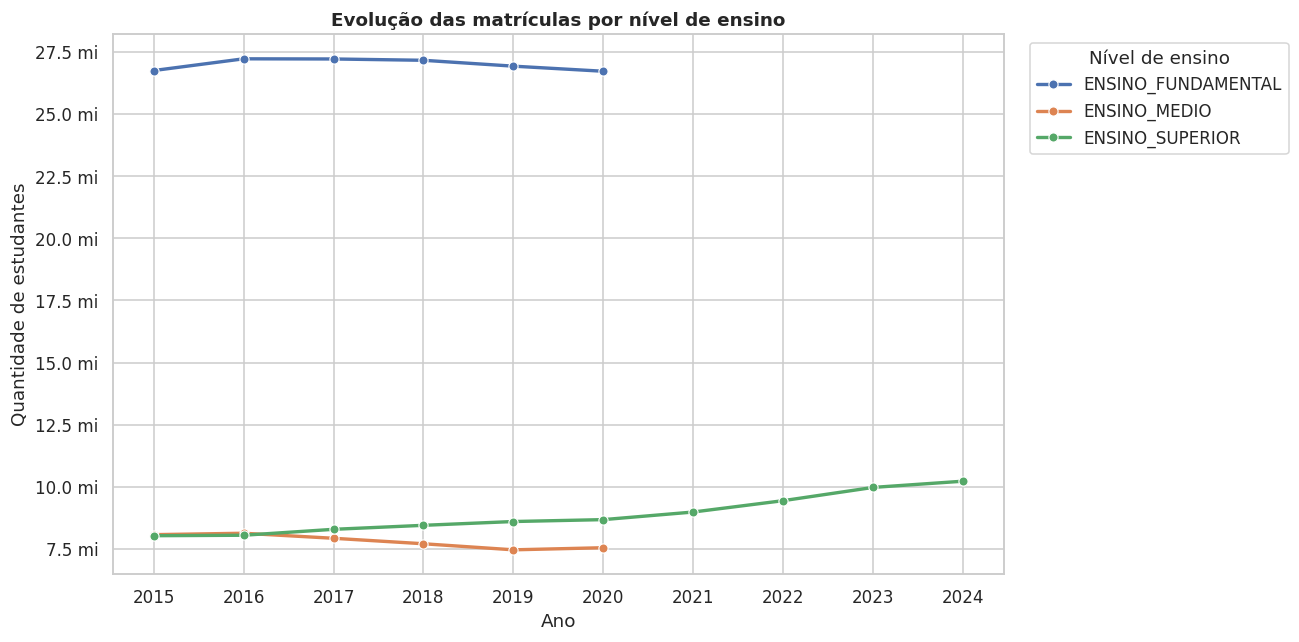

In [7]:
# Evolução do volume de matrículas por nível de ensino
estudantes_por_ano_nivel = (df_001.groupby(['ano', 'nivel_ensino'], as_index=False)
                            .agg(qtd_estudantes=('qtd_estudantes', 'sum'))
                            .sort_values(['ano', 'nivel_ensino']))
display(estudantes_por_ano_nivel.head())

fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(data=estudantes_por_ano_nivel, x='ano', y='qtd_estudantes',
             hue='nivel_ensino', marker='o', linewidth=2.2, ax=ax)
ax.set(title='Evolução das matrículas por nível de ensino',
       xlabel='Ano', ylabel='Quantidade de estudantes')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1e6:.1f} mi'))
ax.set_xticks(sorted(estudantes_por_ano_nivel['ano'].unique()))
ax.legend(title='Nível de ensino', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### **3.2. Distribuição Geográfica e Regional das Matrículas**

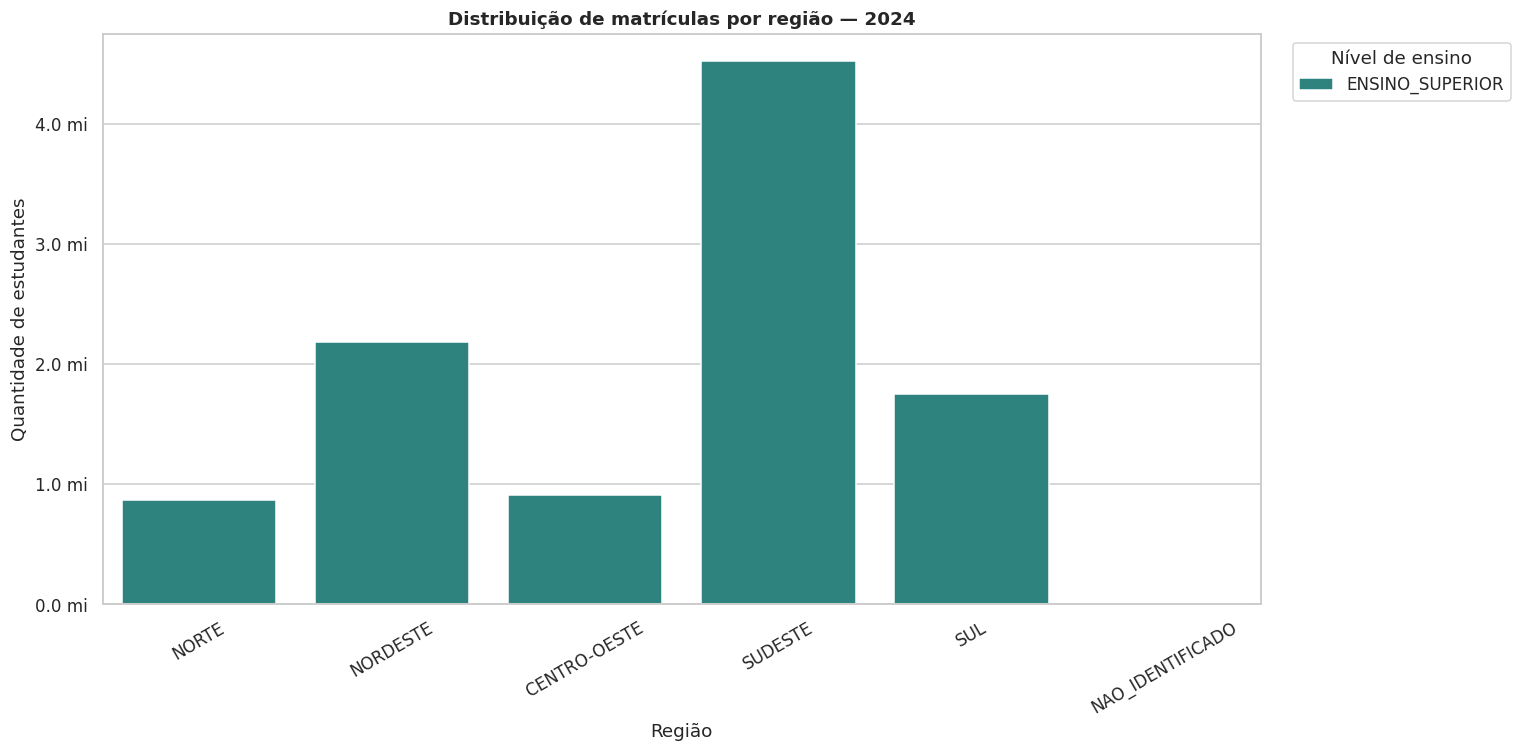

In [8]:
# Distribuição regional no último ano disponível
estudantes_por_regiao = (df_001.groupby(['ano', 'regiao', 'nivel_ensino'], as_index=False)
                         .agg(qtd_estudantes=('qtd_estudantes', 'sum')))
ultimo_ano = estudantes_por_regiao['ano'].max()
estudantes_regiao_ultimo_ano = estudantes_por_regiao[estudantes_por_regiao['ano'] == ultimo_ano]
ordem_regioes = ['NORTE', 'NORDESTE', 'CENTRO-OESTE', 'SUDESTE', 'SUL', 'NAO_IDENTIFICADO']
ordem_regioes = [r for r in ordem_regioes if r in estudantes_regiao_ultimo_ano['regiao'].unique()]

fig, ax = plt.subplots(figsize=(14, 7))
sns.barplot(data=estudantes_regiao_ultimo_ano, x='regiao', y='qtd_estudantes',
            hue='nivel_ensino', order=ordem_regioes, palette='viridis', ax=ax)
ax.set(title=f'Distribuição de matrículas por região — {ultimo_ano}',
       xlabel='Região', ylabel='Quantidade de estudantes')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1e6:.1f} mi'))
ax.tick_params(axis='x', rotation=30)
ax.legend(title='Nível de ensino', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### **3.3. Indicadores de Infraestrutura: Conectividade à Internet na Educação Básica**

,ano,nivel_ensino,numerador,denominador,percentual_ponderado
0,2015,ENSINO_FUNDAMENTAL,2339276428.09,26747160,87.458871
1,2015,ENSINO_MEDIO,779271568.84,8076150,96.490477
2,2016,ENSINO_FUNDAMENTAL,2408090155.02,27219258,88.470088
3,2016,ENSINO_MEDIO,785212151.21,8133040,96.54596
4,2017,ENSINO_FUNDAMENTAL,2350819509.83,27212970,86.385996
5,2017,ENSINO_MEDIO,745182722.83,7930384,93.965528
6,2018,ENSINO_FUNDAMENTAL,2440356668.57,27160106,89.850779
7,2018,ENSINO_MEDIO,748173490.17,7709929,97.040257
8,2019,ENSINO_FUNDAMENTAL,2410926472.74,26923730,89.546525
9,2019,ENSINO_MEDIO,689379939.76,7465891,92.337263


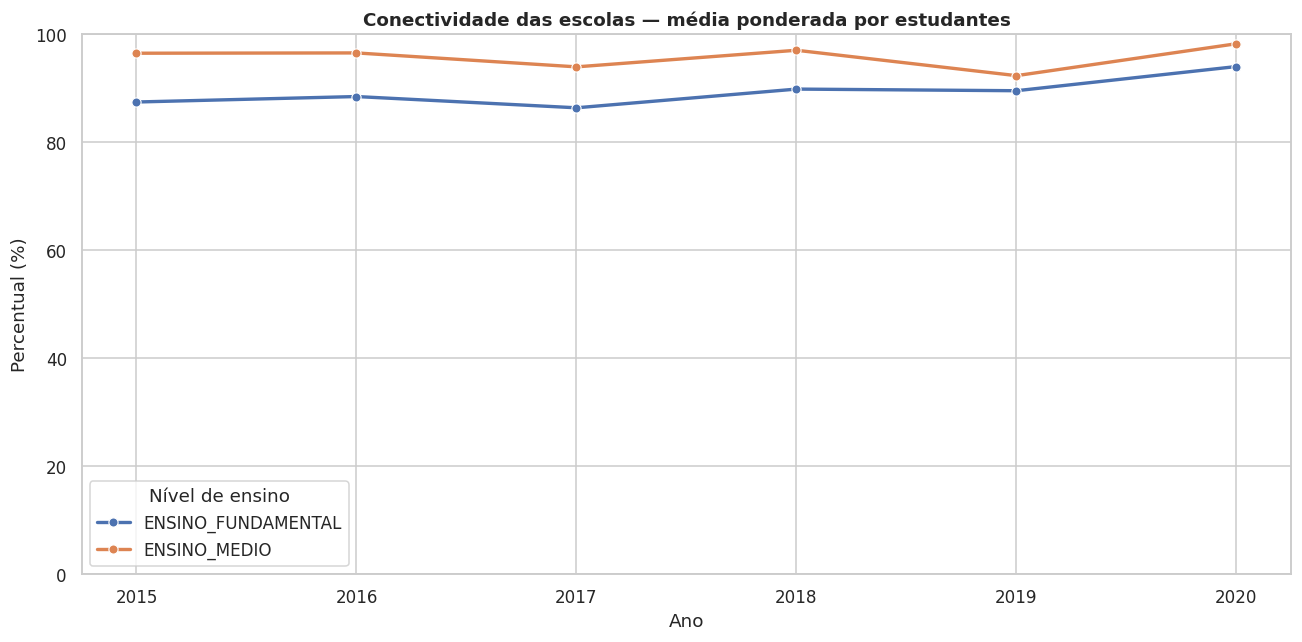

In [9]:
# Evolução da conectividade com média ponderada por quantidade de estudantes
internet_base = df_001.loc[
    df_001['nivel_ensino'].isin(['ENSINO_FUNDAMENTAL', 'ENSINO_MEDIO'])
    & df_001['perc_em_escola_com_internet'].notna(),
    ['ano', 'nivel_ensino', 'perc_em_escola_com_internet', 'qtd_estudantes']
].copy()
internet_base['numerador_ponderado'] = (internet_base['perc_em_escola_com_internet']
                                         * internet_base['qtd_estudantes'])
internet_escola_basic = (internet_base.groupby(['ano', 'nivel_ensino'], as_index=False)
                         .agg(numerador=('numerador_ponderado', 'sum'),
                              denominador=('qtd_estudantes', 'sum')))
internet_escola_basic['percentual_ponderado'] = (
    internet_escola_basic['numerador'] / internet_escola_basic['denominador']
)
display(internet_escola_basic)

fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(data=internet_escola_basic, x='ano', y='percentual_ponderado',
             hue='nivel_ensino', marker='o', linewidth=2.2, ax=ax)
ax.set(title='Conectividade das escolas — média ponderada por estudantes',
       xlabel='Ano', ylabel='Percentual (%)', ylim=(0, 100))
ax.set_xticks(sorted(internet_escola_basic['ano'].unique()))
ax.legend(title='Nível de ensino')
plt.tight_layout()
plt.show()

### **3.4. Análise Demográfica: Distribuição por Sexo e Nível de Ensino**

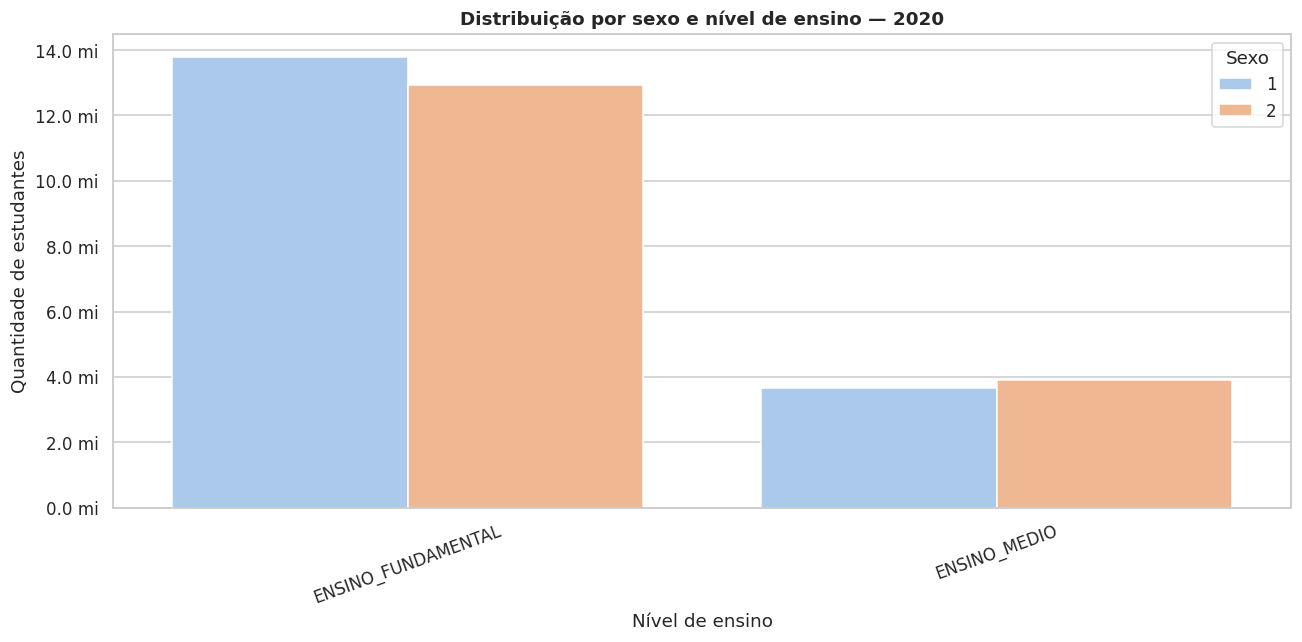

In [10]:
# Distribuição por sexo no último ano disponível
estudantes_por_sexo = (df_001[df_001['sexo'] != 'AGREGADO']
                       .groupby(['ano', 'nivel_ensino', 'sexo'], as_index=False)
                       .agg(qtd_estudantes=('qtd_estudantes', 'sum')))
ultimo_ano_sexo = estudantes_por_sexo['ano'].max()
estudantes_sexo_ultimo_ano = estudantes_por_sexo[estudantes_por_sexo['ano'] == ultimo_ano_sexo]

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=estudantes_sexo_ultimo_ano, x='nivel_ensino', y='qtd_estudantes',
            hue='sexo', palette='pastel', ax=ax)
ax.set(title=f'Distribuição por sexo e nível de ensino — {ultimo_ano_sexo}',
       xlabel='Nível de ensino', ylabel='Quantidade de estudantes')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1e6:.1f} mi'))
ax.tick_params(axis='x', rotation=20)
ax.legend(title='Sexo')
plt.tight_layout()
plt.show()

### **3.5. Análise de Diversidade: Distribuição de Estudantes por Raça/Cor**

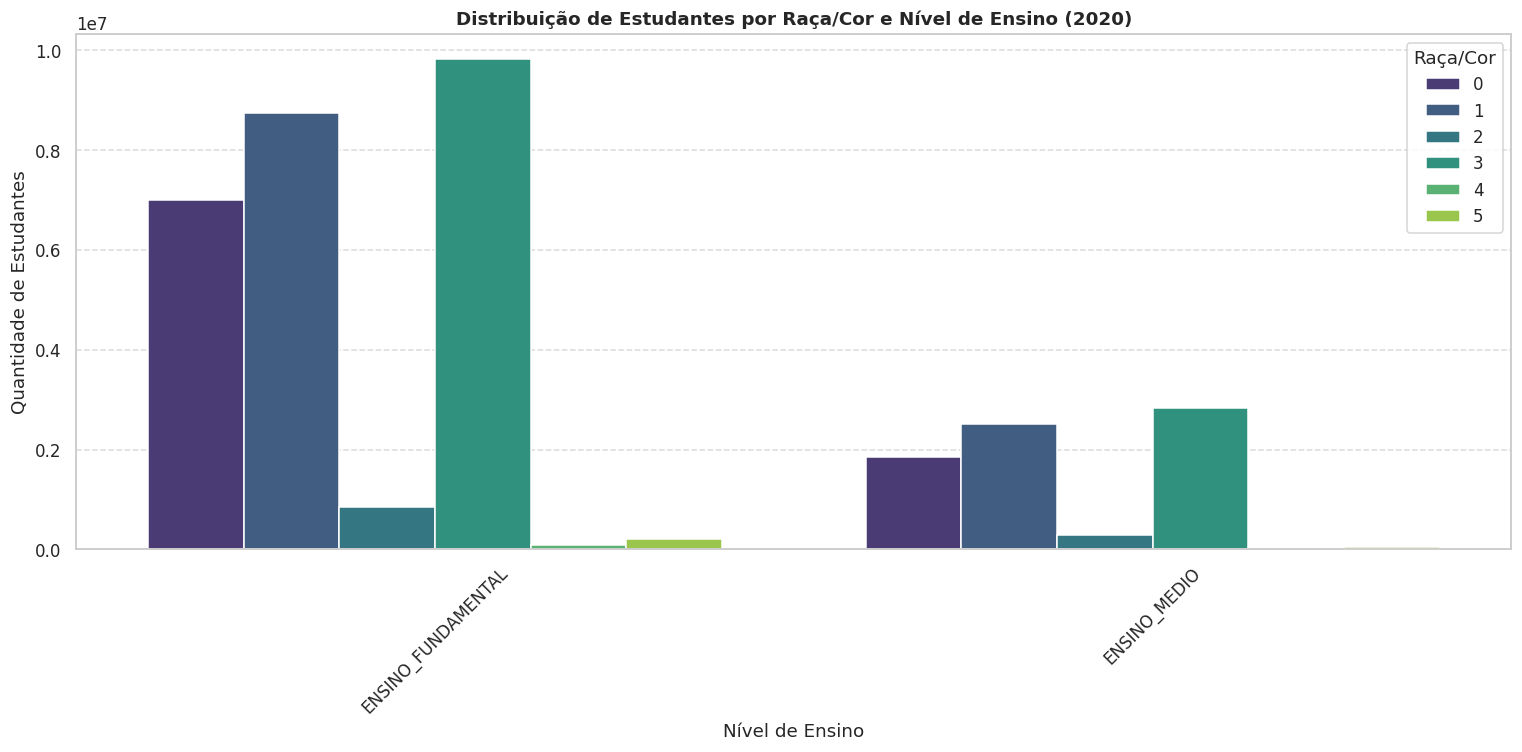

In [11]:
# Filtra o DataFrame para remover entradas onde 'raca_cor' é 'AGREGADO'
estudantes_por_raca = df_001[df_001['raca_cor'] != 'AGREGADO'].groupby(['ano', 'nivel_ensino', 'raca_cor'])['qtd_estudantes'].sum().reset_index()

# Encontra o último ano disponível para focar a análise
ultimo_ano_raca = estudantes_por_raca['ano'].max()
# Filtra os dados para o último ano
estudantes_raca_ultimo_ano = estudantes_por_raca[estudantes_por_raca['ano'] == ultimo_ano_raca]

# Cria uma figura para o gráfico com um tamanho específico
plt.figure(figsize=(14, 7))
# Gera um gráfico de barras que mostra a quantidade de estudantes por nível de ensino, separados por raça/cor
sns.barplot(data=estudantes_raca_ultimo_ano, x='nivel_ensino', y='qtd_estudantes', hue='raca_cor', palette='viridis')
plt.title(f'Distribuição de Estudantes por Raça/Cor e Nível de Ensino ({ultimo_ano_raca})') # Define o título do gráfico com o ano
plt.xlabel('Nível de Ensino') # Define o rótulo do eixo X
plt.ylabel('Quantidade de Estudantes') # Define o rótulo do eixo Y
plt.xticks(rotation=45) # Rotaciona os rótulos do eixo X
plt.grid(axis='y', linestyle='--', alpha=0.7) # Adiciona uma grade horizontal
plt.legend(title='Raça/Cor') # Adiciona uma legenda para raça/cor
plt.tight_layout() # Ajusta o layout
plt.show() # Exibe o gráfico

### **3.6. Análise Geracional: Distribuição por Faixa Etária e Nível de Ensino**

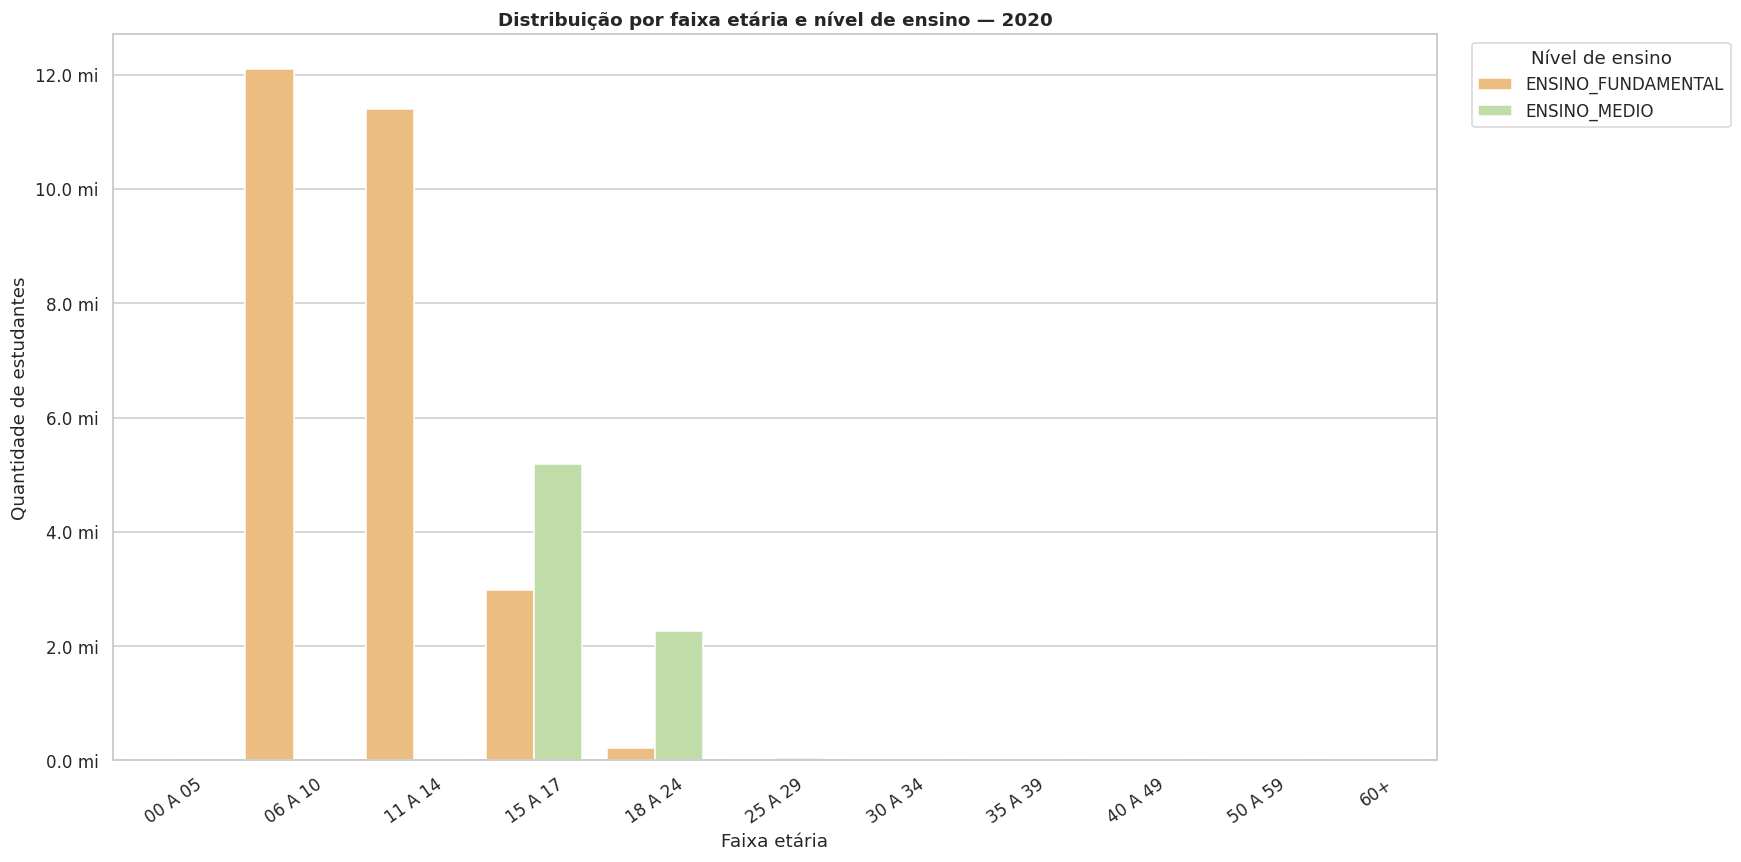

In [12]:
# Distribuição por faixa etária no último ano disponível
estudantes_por_faixa_etaria = (df_001[df_001['faixa_etaria'] != 'AGREGADO_SUPERIOR']
                                .groupby(['ano', 'nivel_ensino', 'faixa_etaria'], as_index=False)
                                .agg(qtd_estudantes=('qtd_estudantes', 'sum')))
ultimo_ano_idade = estudantes_por_faixa_etaria['ano'].max()
estudantes_idade_ultimo_ano = estudantes_por_faixa_etaria[
    estudantes_por_faixa_etaria['ano'] == ultimo_ano_idade
].copy()
ordem_faixas = ['00 A 05', '06 A 10', '11 A 14', '15 A 17', '18 A 24',
                '25 A 29', '30 A 34', '35 A 39', '40 A 49', '50 A 59', '60+']
estudantes_idade_ultimo_ano['faixa_etaria'] = pd.Categorical(
    estudantes_idade_ultimo_ano['faixa_etaria'], categories=ordem_faixas, ordered=True
)

fig, ax = plt.subplots(figsize=(16, 8))
sns.barplot(data=estudantes_idade_ultimo_ano.sort_values('faixa_etaria'),
            x='faixa_etaria', y='qtd_estudantes', hue='nivel_ensino',
            palette='Spectral', ax=ax)
ax.set(title=f'Distribuição por faixa etária e nível de ensino — {ultimo_ano_idade}',
       xlabel='Faixa etária', ylabel='Quantidade de estudantes')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1e6:.1f} mi'))
ax.tick_params(axis='x', rotation=35)
ax.legend(title='Nível de ensino', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### **3.7. Inclusão Social: Taxa de Estudantes com Deficiência ao Longo do Tempo**

,ano,nivel_ensino,numerador,denominador,percentual_ponderado
0,2015,ENSINO_FUNDAMENTAL,66304042.69,26747160,2.478919
1,2015,ENSINO_MEDIO,6576052.53,8076150,0.814256
2,2015,ENSINO_SUPERIOR,3797982.88,8033574,0.472764
3,2016,ENSINO_FUNDAMENTAL,70178295.24,27219258,2.578259
4,2016,ENSINO_MEDIO,7506187.15,8133040,0.922925
5,2016,ENSINO_SUPERIOR,3591429.66,8052254,0.446015
6,2017,ENSINO_FUNDAMENTAL,76544233.2,27212970,2.812785
7,2017,ENSINO_MEDIO,9427120.92,7930384,1.188734
8,2017,ENSINO_SUPERIOR,3828830.92,8290911,0.461811
9,2018,ENSINO_FUNDAMENTAL,83666029.78,27160106,3.080475


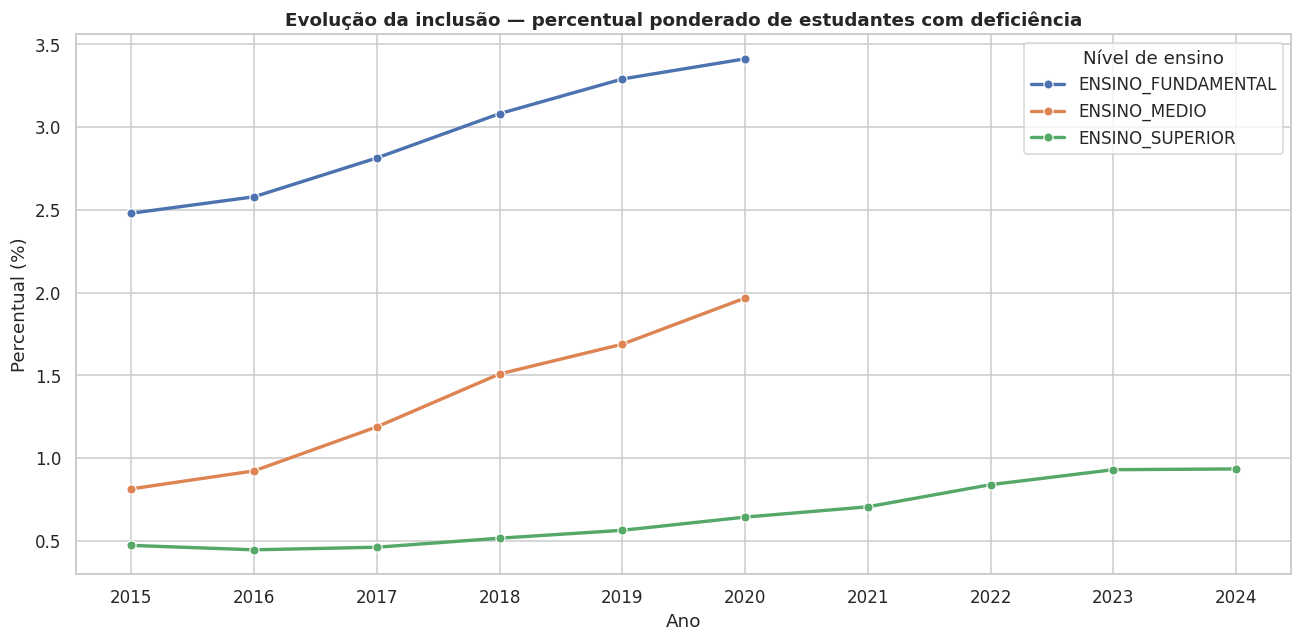

In [13]:
# Evolução da inclusão: média ponderada de estudantes com deficiência
def_base = df_001.loc[
    df_001['perc_com_deficiencia'].notna(),
    ['ano', 'nivel_ensino', 'perc_com_deficiencia', 'qtd_estudantes']
].copy()
def_base['numerador_ponderado'] = def_base['perc_com_deficiencia'] * def_base['qtd_estudantes']
deficiencia_por_nivel = (def_base.groupby(['ano', 'nivel_ensino'], as_index=False)
                         .agg(numerador=('numerador_ponderado', 'sum'),
                              denominador=('qtd_estudantes', 'sum')))
deficiencia_por_nivel['percentual_ponderado'] = (
    deficiencia_por_nivel['numerador'] / deficiencia_por_nivel['denominador']
)
display(deficiencia_por_nivel)

fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(data=deficiencia_por_nivel, x='ano', y='percentual_ponderado',
             hue='nivel_ensino', marker='o', linewidth=2.2, ax=ax)
ax.set(title='Evolução da inclusão — percentual ponderado de estudantes com deficiência',
       xlabel='Ano', ylabel='Percentual (%)')
ax.set_xticks(sorted(deficiencia_por_nivel['ano'].unique()))
ax.legend(title='Nível de ensino')
plt.tight_layout()
plt.show()

### **3.8. Análise Institucional: Dependência Administrativa (Rede Pública vs. Privada)**

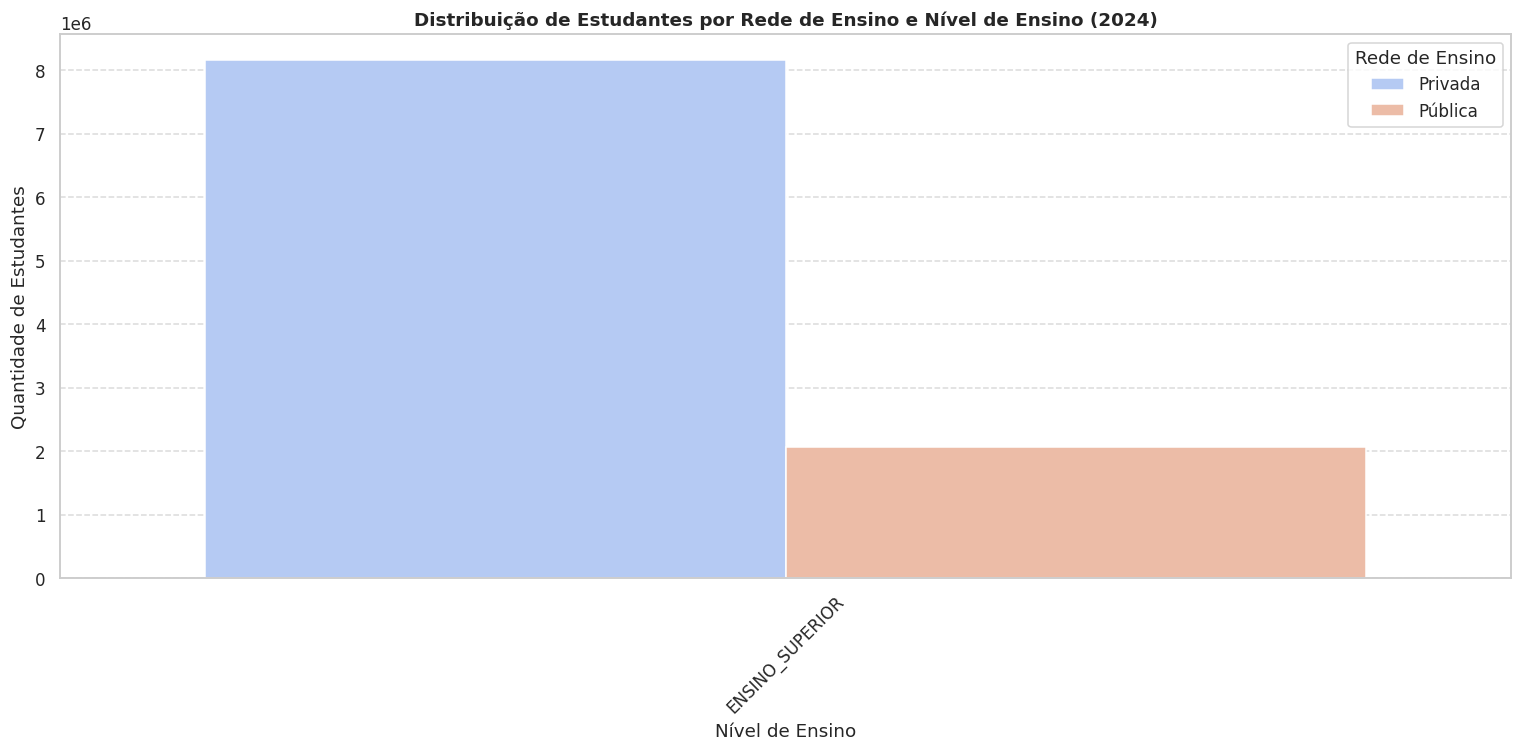

In [14]:
# Filtra o DataFrame para remover entradas onde 'rede' é 'Não Informado'
estudantes_por_rede = df_001[df_001['rede'] != 'Não Informado'].groupby(['ano', 'rede', 'nivel_ensino'])['qtd_estudantes'].sum().reset_index()

# Encontra o último ano disponível para a análise
ultimo_ano_rede = estudantes_por_rede['ano'].max()
# Filtra os dados para o último ano
estudantes_rede_ultimo_ano = estudantes_por_rede[estudantes_por_rede['ano'] == ultimo_ano_rede]

# Cria uma figura para o gráfico com tamanho especificado
plt.figure(figsize=(14, 7))
# Gera um gráfico de barras mostrando a distribuição de estudantes por nível de ensino, separados por rede (pública/privada)
sns.barplot(data=estudantes_rede_ultimo_ano, x='nivel_ensino', y='qtd_estudantes', hue='rede', palette='coolwarm')
plt.title(f'Distribuição de Estudantes por Rede de Ensino e Nível de Ensino ({ultimo_ano_rede})') # Define o título
plt.xlabel('Nível de Ensino') # Define o rótulo do eixo X
plt.ylabel('Quantidade de Estudantes') # Define o rótulo do eixo Y
plt.xticks(rotation=45) # Rotaciona os rótulos do eixo X
plt.grid(axis='y', linestyle='--', alpha=0.7) # Adiciona uma grade horizontal
plt.legend(title='Rede de Ensino') # Adiciona uma legenda
plt.tight_layout() # Ajusta o layout
plt.show() # Exibe o gráfico

### **3.9. Políticas de permanência: assistência e recursos no Ensino Superior**

,ano,qtd_financiamento,qtd_reserva_vaga,qtd_apoio_social,qtd_atividade_extracurricular,qtd_mobilidade_academica
0,2015,2732371,350373,791898,1229880,23094
1,2016,2798323,418652,1057724,1282752,10391
2,2017,2907747,477411,874699,1350237,8018
3,2018,3003974,516643,888820,1405879,8237
4,2019,2988554,570695,866857,1467722,8366


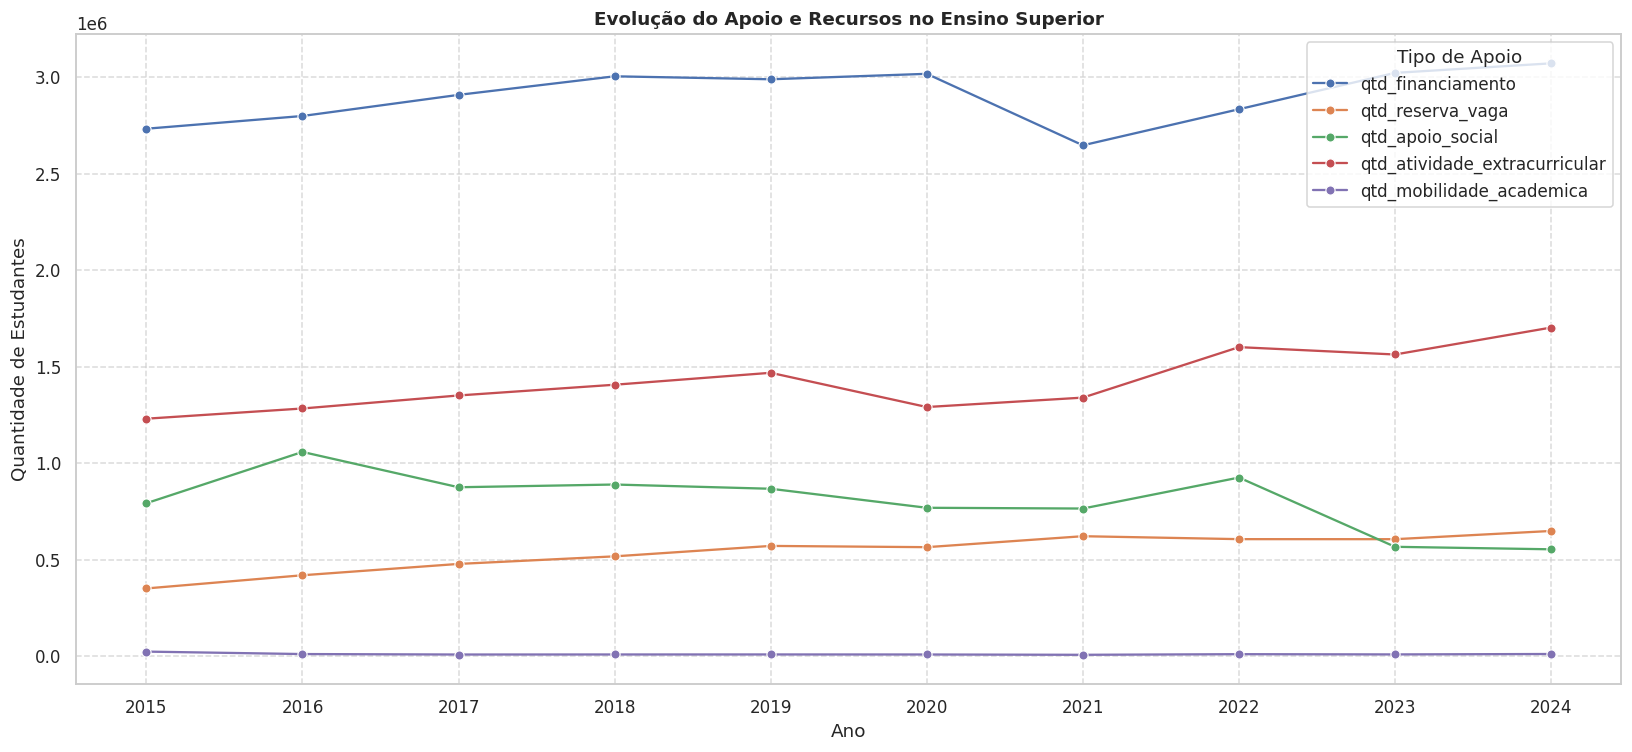

In [15]:
# Filtra o DataFrame para considerar apenas dados do 'ENSINO_SUPERIOR'
# Agrupa por 'ano' e soma as quantidades de diferentes tipos de apoio e recursos
apoio_superior = df_001[df_001['nivel_ensino'] == 'ENSINO_SUPERIOR'].groupby('ano')[['qtd_financiamento', 'qtd_reserva_vaga', 'qtd_apoio_social', 'qtd_atividade_extracurricular', 'qtd_mobilidade_academica']].sum().reset_index()

# Exibe as primeiras linhas da tabela resultante
display(apoio_superior.head())

# Transforma o DataFrame de formato 'wide' para 'long' para facilitar a visualização com seaborn
# Isso empilha as colunas de quantidade de apoio em uma única coluna 'Quantidade de Estudantes'
apoio_superior_long = apoio_superior.melt(id_vars='ano', var_name='Tipo de Apoio', value_name='Quantidade de Estudantes')

# Cria uma figura para o gráfico com tamanho especificado
plt.figure(figsize=(15, 7))
# Gera um gráfico de linha mostrando a evolução dos diferentes tipos de apoio e recursos no Ensino Superior
sns.lineplot(data=apoio_superior_long, x='ano', y='Quantidade de Estudantes', hue='Tipo de Apoio', marker='o')
plt.title('Evolução do Apoio e Recursos no Ensino Superior') # Define o título
plt.xlabel('Ano') # Define o rótulo do eixo X
plt.ylabel('Quantidade de Estudantes') # Define o rótulo do eixo Y
plt.grid(True, linestyle='--', alpha=0.7) # Adiciona uma grade
plt.xticks(apoio_superior_long['ano'].unique()) # Define os ticks do eixo X
plt.legend(title='Tipo de Apoio') # Adiciona uma legenda
plt.tight_layout() # Ajusta o layout
plt.show() # Exibe o gráfico

## 4. Conclusões e próximos passos

Este notebook entrega a camada exploratória do projeto: consulta parametrizada, diagnóstico da base, cobertura temporal e visualizações para apoiar perguntas de negócio e pesquisa.

### Cuidados de interpretação

- Os resultados são descritivos e não estabelecem relações causais.
- A comparação entre níveis de ensino deve respeitar as diferenças de fonte e granularidade.
- Os percentuais nacionais apresentados nas análises específicas são ponderados por `qtd_estudantes` quando indicado no título.
- A janela dinâmica só incorpora anos efetivamente publicados na Base dos Dados/INEP.

### Próximas análises

1. Executar `02_base_infraestrutura_municipio_ano.sql` e `03_indice_infraestrutura.sql` no BigQuery.
2. Desenvolver clusterização municipal com padronização e silhouette score.
3. Desenvolver classificação temporal do quartil de infraestrutura do ano seguinte.
4. Comparar baselines e modelos de previsão por UF.
5. Atualizar o Power BI e publicar os principais achados no portfólio.